# Round 2: fine-tune on all MIDV-500 + MIDV-2019 frames
**Nothing in this notebook has been executed by the assistant. Run its code cells in order yourself.** Run All prepares the dataset, measures a baseline, trains, then compares validation performance.

Every video frame is used (stride 1). Flat reference/template images and videos are excluded. Expect about 21,000 frames before filtering, with approximately 12,600 in training. Images are resized to max side 960 as in round 1; training remains at 640px. Every frame means full temporal sampling, not full source resolution.

Estimated training duration on your RTX 5060 Ti: **1–2 hours for 20 epochs**, plus preparation and validation comparisons. This estimate scales your observed 17.5-minute run by training-image count. Actual elapsed time and ETA are printed. Preparation reports its own progress separately.

We start from your round-1 best.pt, not the COCO checkpoint, with a fresh optimizer at a low learning rate. MIDV-500 examples remain in the training mix to limit forgetting. The original checkpoint, datasets, test reports and manual photos are preserved.


In [1]:
from pathlib import Path
from datetime import datetime, timedelta
from collections import Counter
import hashlib
import json
import sys
import time
import cv2
import numpy as np
import torch
import yaml
from ultralytics import YOLO

PROJECT = Path('/home/joe/PycharmProjects/id-capture')
ROOTS = {
    'midv500': Path('/home/joe/training-data/midv500'),
    'midv2019': Path('/home/joe/training-data/midv2019'),
}
FIRST_DATA = PROJECT / 'training/data/midv500_yolo'
DATA = PROJECT / 'training/data/midv_round2_all_frames'
RUNS = PROJECT / 'training/runs'
INITIAL_WEIGHTS = PROJECT / 'training/runs/yolo11n_midv500_20261012_095837_074736/weights/best.pt'
EPOCHS = 20
BATCH = 16
IMGSZ = 640
MAX_SIDE = 960
SEED = 42
CONFIDENCE = 0.25
NAMES = {0: 'driving_licence', 1: 'passport'}

assert INITIAL_WEIGHTS.is_file(), INITIAL_WEIGHTS
assert all(root.is_dir() for root in ROOTS.values()), ROOTS
assert torch.cuda.is_available(), 'CUDA required; select your project kernel with CUDA-enabled PyTorch.'
probe = torch.randn(256, 256, device='cuda')
result = probe @ probe.T
torch.cuda.synchronize()
assert result.is_cuda and torch.isfinite(result).all().item()
print('Python:', sys.executable)
print('PyTorch:', torch.__version__, '| CUDA runtime:', torch.version.cuda)
print('GPU:', torch.cuda.get_device_name(0))
print('PASS: CUDA matrix operation on', result.device)
del probe, result
torch.cuda.empty_cache()
print('Starting checkpoint:', INITIAL_WEIGHTS)
print('Prepared dataset output:', DATA)


Python: /home/joe/.cache/pypoetry/virtualenvs/id-capture-MVkOamB--py3.12/bin/python3.12
PyTorch: 2.14.1+cu130 | CUDA runtime: 13.0
GPU: NVIDIA GeForce RTX 5060 Ti
PASS: CUDA matrix operation on cuda:0
Starting checkpoint: /home/joe/PycharmProjects/id-capture/training/runs/yolo11n_midv500_20261012_095837_074736/weights/best.pt
Prepared dataset output: /home/joe/PycharmProjects/id-capture/training/data/midv_round2_all_frames


## Split and comparison rules
Reuse the document-to-split assignment from round 1 for both sources. MIDV-2019 reuses the same document templates/specimens, so random frame or independent source splitting would leak examples across training and evaluation.

Only train images update weights. Validation selects the best checkpoint and compares round 1 against round 2 on identical images. Test frames are prepared but are not evaluated in this notebook. The original test results have already been inspected, so this is a development experiment, not a new blind benchmark. Keep all uploaded phone photos out of training.

Operating metrics use fixed confidence 0.25 and localization IoU 0.50. Goals: recall >= 90% for each target class and negative-image false-positive rate <= 5%. Improvement criterion: lower false-positive rate while keeping both recalls at least 90% and no more than 1 percentage point below the measured baseline. Results may improve or regress; the notebook reports both.

Other document types receive empty labels. Internal passports and passport cards remain negatives, matching round 1. Check whether this class definition matches your product requirements before changing it.


In [2]:
old_manifest = json.loads((FIRST_DATA / 'manifest.json').read_text())
assignment = old_manifest['config']['assignment']
assert set(assignment.values()) == {'train', 'val', 'test'}

def document_class(name):
    if '_drvlic' in name:
        return 0
    if '_passport' in name and 'passportcard' not in name:
        return 1
    return None

jobs = []
folder_sets = {}
extensions = {'.tif', '.tiff', '.jpg', '.jpeg', '.png'}
for source, root in ROOTS.items():
    folders = sorted(p for p in root.iterdir() if p.is_dir() and (p / 'images').is_dir())
    folder_sets[source] = {p.name for p in folders}
    assert folder_sets[source] == set(assignment), (source, 'Document folder mismatch')
    for folder in folders:
        split = assignment[folder.name]
        for clip in sorted(p for p in (folder / 'images').iterdir() if p.is_dir()):
            for image in sorted(p for p in clip.iterdir() if p.suffix.lower() in extensions):
                annotation = folder / 'ground_truth' / clip.name / (image.stem + '.json')
                assert annotation.is_file(), annotation
                jobs.append({
                    'source': source, 'document': folder.name, 'clip': clip.name,
                    'original': str(image), 'annotation': str(annotation),
                    'split': split, 'class': document_class(folder.name),
                })
print('All video frames (no stride):', len(jobs))
print('Frames by source:', dict(Counter(job['source'] for job in jobs)))
for split in ('train', 'val', 'test'):
    part = [job for job in jobs if job['split'] == split]
    print(split, len(part), dict(Counter(NAMES.get(job['class'], 'negative') for job in part)))
    assert {job['class'] for job in part} == {0, 1, None}
sets = {split: {job['document'] for job in jobs if job['split'] == split} for split in ('train', 'val', 'test')}
assert not (sets['train'] & sets['val'] or sets['train'] & sets['test'] or sets['val'] & sets['test'])
print('PASS: all frames of a document remain in the same split across both datasets.')
config = {
    'sources': {source: str(root) for source, root in ROOTS.items()},
    'assignment': assignment, 'frame_stride': 1, 'max_side': MAX_SIDE,
    'seed': SEED, 'frame_count': len(jobs), 'schema': 1,
    'job_list_sha256': hashlib.sha256(json.dumps(jobs, sort_keys=True).encode()).hexdigest(),
}


All video frames (no stride): 21000
Frames by source: {'midv500': 15000, 'midv2019': 6000}
train 12600 {'negative': 5880, 'driving_licence': 3360, 'passport': 3360}
val 4200 {'negative': 2100, 'passport': 1260, 'driving_licence': 840}
test 4200 {'passport': 1260, 'driving_licence': 840, 'negative': 2100}
PASS: all frames of a document remain in the same split across both datasets.


In [3]:
# Prepare derived JPEG images and YOLO labels. Source files are read only.
prepared_manifest = DATA / 'manifest.json'
config_path = DATA / 'preparation_config.json'
if DATA.exists():
    assert config_path.is_file(), 'Unexpected output directory; choose a fresh DATA path.'
    assert json.loads(config_path.read_text()) == config, 'Configuration changed; choose a fresh DATA path.'
else:
    DATA.mkdir(parents=True)
    config_path.write_text(json.dumps(config, indent=2))
for split in ('train', 'val', 'test'):
    (DATA / 'images' / split).mkdir(parents=True, exist_ok=True)
    (DATA / 'labels' / split).mkdir(parents=True, exist_ok=True)

if prepared_manifest.exists():
    prepared = json.loads(prepared_manifest.read_text())
    assert prepared['config'] == config
    records = prepared['records']
    skipped = Counter(prepared['skipped'])
    assert all(Path(r['image']).is_file() and Path(r['label']).is_file() for r in records)
    print('Reusing complete prepared dataset:', len(records), 'images')
else:
    # Safe to restart after an interruption: validate/recreate derived files only.
    started = time.perf_counter()
    records = []
    skipped = Counter()
    for index, job in enumerate(jobs, 1):
        src = Path(job['original'])
        stem = job['source'] + '__' + job['document'] + '__' + job['clip'] + '__' + src.stem
        dst = DATA / 'images' / job['split'] / (stem + '.jpg')
        label = DATA / 'labels' / job['split'] / (stem + '.txt')
        image = cv2.imread(str(src))
        assert image is not None, src
        h, w = image.shape[:2]
        quad = np.asarray(json.loads(Path(job['annotation']).read_text())['quad'], dtype=float)
        assert quad.shape == (4, 2) and np.isfinite(quad).all(), job['annotation']
        lo = np.maximum(quad.min(axis=0), [0, 0])
        hi = np.minimum(quad.max(axis=0), [w, h])
        if np.any(hi <= lo):
            skipped[job['source'] + ':document_outside_image'] += 1
        else:
            box = np.r_[((lo + hi) / 2) / [w, h], (hi - lo) / [w, h]]
            assert np.all((box >= 0) & (box <= 1))
            scale = min(1.0, MAX_SIDE / max(h, w))
            if scale < 1:
                image = cv2.resize(image, (round(w * scale), round(h * scale)), interpolation=cv2.INTER_AREA)
            assert cv2.imwrite(str(dst), image, [cv2.IMWRITE_JPEG_QUALITY, 95]), dst
            text_label = '' if job['class'] is None else str(job['class']) + ' ' + ' '.join(f'{v:.8f}' for v in box) + chr(10)
            label.write_text(text_label)
            records.append({**job, 'image': str(dst), 'label': str(label)})
        if index % 200 == 0 or index == len(jobs):
            elapsed = time.perf_counter() - started
            eta = elapsed / index * (len(jobs) - index)
            print(f'Preparation: {100 * index / len(jobs):.1f}% | {index}/{len(jobs)} | Elapsed: {timedelta(seconds=int(elapsed))} | ETA: {timedelta(seconds=int(eta))}', flush=True)
    prepared_manifest.write_text(json.dumps({'config': config, 'records': records, 'skipped': dict(skipped)}, indent=2))

DATA_YAML = DATA / 'data.yaml'
DATA_YAML.write_text(yaml.safe_dump({
    'path': str(DATA), 'train': 'images/train', 'val': 'images/val',
    'test': 'images/test', 'names': NAMES,
}, sort_keys=False))
print('Skipped fully out-of-frame documents:', dict(skipped))
for split in ('train', 'val', 'test'):
    part = [r for r in records if r['split'] == split]
    assert {r['class'] for r in part} == {0, 1, None}
    print(split, len(part), dict(Counter(NAMES.get(r['class'], 'negative') for r in part)))
val_records = [r for r in records if r['split'] == 'val']
print('Dataset ready:', DATA_YAML)


Preparation: 1.0% | 200/21000 | Elapsed: 0:00:04 | ETA: 0:08:05
Preparation: 1.9% | 400/21000 | Elapsed: 0:00:10 | ETA: 0:09:23
Preparation: 2.9% | 600/21000 | Elapsed: 0:00:16 | ETA: 0:09:37
Preparation: 3.8% | 800/21000 | Elapsed: 0:00:22 | ETA: 0:09:17
Preparation: 4.8% | 1000/21000 | Elapsed: 0:00:29 | ETA: 0:09:59
Preparation: 5.7% | 1200/21000 | Elapsed: 0:00:35 | ETA: 0:09:39
Preparation: 6.7% | 1400/21000 | Elapsed: 0:00:40 | ETA: 0:09:24
Preparation: 7.6% | 1600/21000 | Elapsed: 0:00:45 | ETA: 0:09:10
Preparation: 8.6% | 1800/21000 | Elapsed: 0:00:50 | ETA: 0:08:57
Preparation: 9.5% | 2000/21000 | Elapsed: 0:00:56 | ETA: 0:08:54
Preparation: 10.5% | 2200/21000 | Elapsed: 0:01:02 | ETA: 0:08:51
Preparation: 11.4% | 2400/21000 | Elapsed: 0:01:08 | ETA: 0:08:51
Preparation: 12.4% | 2600/21000 | Elapsed: 0:01:14 | ETA: 0:08:47
Preparation: 13.3% | 2800/21000 | Elapsed: 0:01:24 | ETA: 0:09:07
Preparation: 14.3% | 3000/21000 | Elapsed: 0:01:31 | ETA: 0:09:06
Preparation: 15.2% | 320

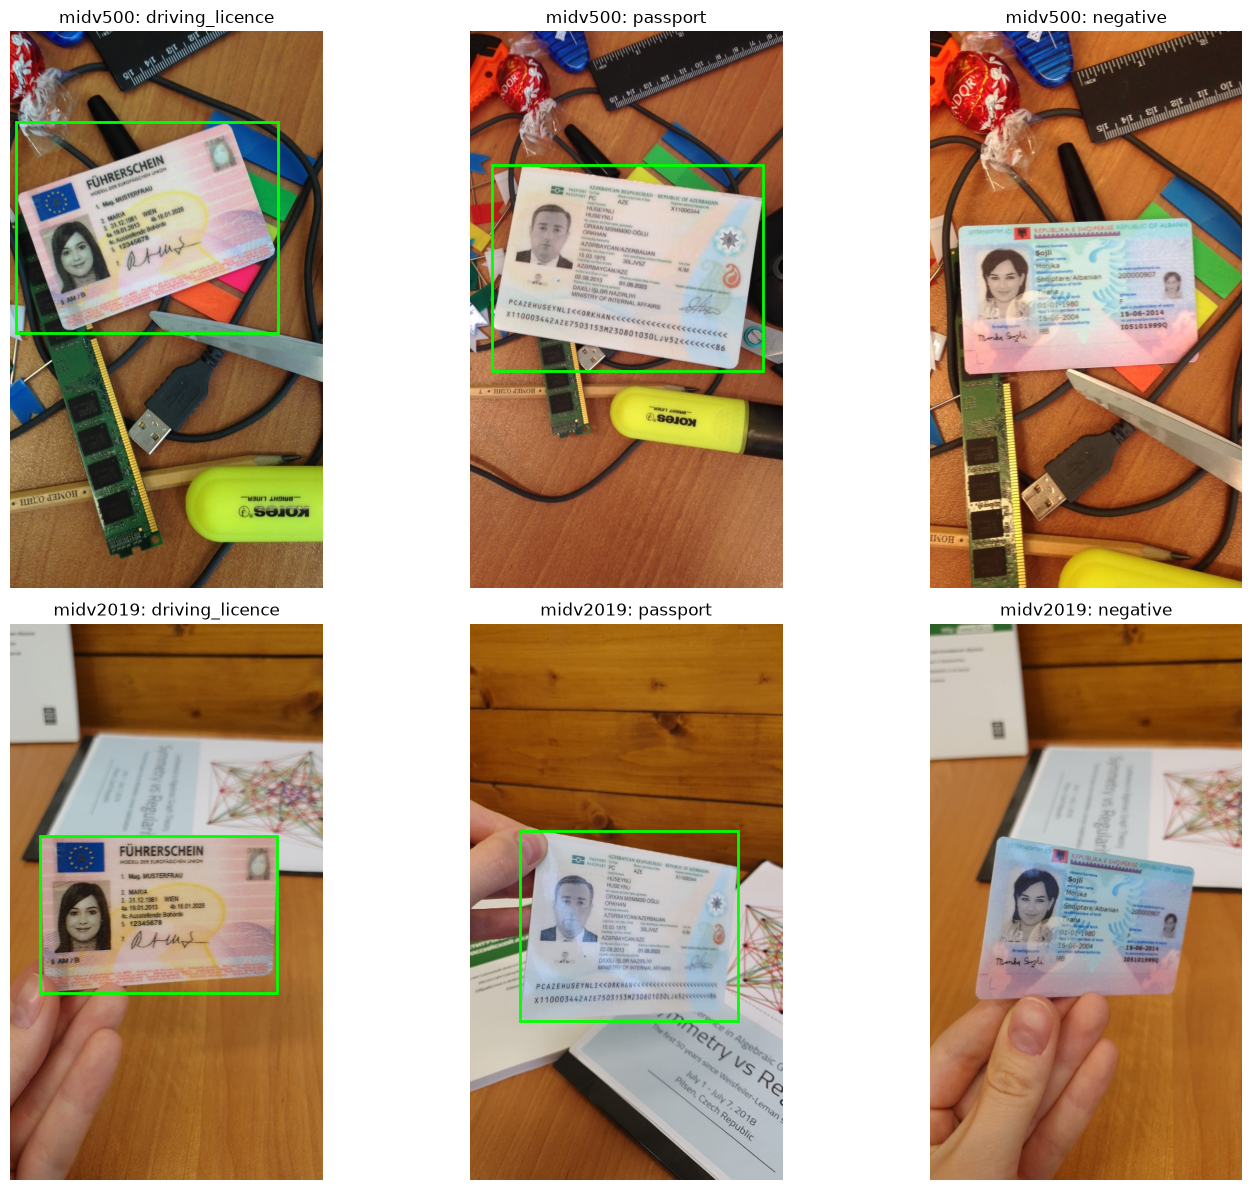

In [4]:
# Inspect a labelled training frame from each dataset/class before training.
from matplotlib.patches import Rectangle
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(15, 12))
for row, source in enumerate(ROOTS):
    for column, cls in enumerate((0, 1, None)):
        rec = next(r for r in records if r['source'] == source and r['split'] == 'train' and r['class'] == cls)
        image = cv2.cvtColor(cv2.imread(rec['image']), cv2.COLOR_BGR2RGB)
        ax = axes[row, column]
        ax.imshow(image)
        if cls is not None:
            _, cx, cy, bw, bh = map(float, Path(rec['label']).read_text().split())
            h, w = image.shape[:2]
            ax.add_patch(Rectangle(((cx - bw/2)*w, (cy - bh/2)*h), bw*w, bh*h, fill=False, edgecolor='lime', linewidth=2))
        ax.set_title(source + ': ' + NAMES.get(cls, 'negative'))
        ax.axis('off')
plt.tight_layout()
plt.show()


In [5]:
def box_iou(boxes, target):
    overlap = np.maximum(0, np.minimum(boxes[:, 2:], target[2:]) - np.maximum(boxes[:, :2], target[:2]))
    intersection = overlap.prod(axis=1)
    areas = np.maximum(0, boxes[:, 2:] - boxes[:, :2]).prod(axis=1)
    target_area = np.maximum(0, target[2:] - target[:2]).prod()
    return intersection / np.maximum(areas + target_area - intersection, 1e-9)

def validation_summary(checkpoint, name):
    candidate = YOLO(str(checkpoint))
    assert candidate.names == NAMES, (candidate.names, NAMES)
    hits = Counter()
    totals = Counter()
    false_positives = Counter()
    type_matches = 0
    started = time.perf_counter()
    for offset in range(0, len(val_records), BATCH):
        batch_records = val_records[offset:offset + BATCH]
        predictions = candidate.predict(
            source=[r['image'] for r in batch_records], device=0,
            imgsz=IMGSZ, conf=CONFIDENCE, verbose=False,
        )
        for rec, pred in zip(batch_records, predictions):
            cls = rec['class']
            keys = ('combined', rec['source'])
            for key in keys:
                totals[(key, cls)] += 1
            boxes = pred.boxes
            top_type = None if len(boxes) == 0 else int(boxes.cls[boxes.conf.argmax()].item())
            type_matches += top_type == cls
            if cls is None:
                for key in keys:
                    false_positives[key] += int(len(boxes) > 0)
                continue
            cx, cy, bw, bh = map(float, Path(rec['label']).read_text().split()[1:])
            target = np.array([cx - bw/2, cy - bh/2, cx + bw/2, cy + bh/2])
            correct_class = boxes.cls.cpu().numpy().astype(int) == cls
            hit = correct_class.any() and (box_iou(boxes.xyxyn.cpu().numpy()[correct_class], target) >= 0.50).any()
            for key in keys:
                hits[(key, cls)] += int(hit)
        if offset % (BATCH * 20) == 0 or offset + BATCH >= len(val_records):
            done = min(offset + BATCH, len(val_records))
            print(f'{name} validation: {100 * done / len(val_records):.1f}% | {done}/{len(val_records)}', flush=True)
    report = {
        'checkpoint': str(checkpoint), 'split': 'val', 'confidence': CONFIDENCE,
        'iou': 0.50, 'images': len(val_records),
        'type_accuracy': type_matches / len(val_records),
        'elapsed_seconds': time.perf_counter() - started,
        'by_source': {},
    }
    for key in ('combined', *ROOTS):
        report['by_source'][key] = {
            'driving_licence_recall': hits[(key, 0)] / totals[(key, 0)],
            'passport_recall': hits[(key, 1)] / totals[(key, 1)],
            'negative_false_positive_rate': false_positives[key] / totals[(key, None)],
        }
    del candidate
    torch.cuda.empty_cache()
    return report

BASELINE = validation_summary(INITIAL_WEIGHTS, 'Round 1 baseline')
print(json.dumps(BASELINE, indent=2))


Round 1 baseline validation: 0.4% | 16/4162
Round 1 baseline validation: 8.1% | 336/4162
Round 1 baseline validation: 15.8% | 656/4162
Round 1 baseline validation: 23.5% | 976/4162
Round 1 baseline validation: 31.1% | 1296/4162
Round 1 baseline validation: 38.8% | 1616/4162
Round 1 baseline validation: 46.5% | 1936/4162
Round 1 baseline validation: 54.2% | 2256/4162
Round 1 baseline validation: 61.9% | 2576/4162
Round 1 baseline validation: 69.6% | 2896/4162
Round 1 baseline validation: 77.3% | 3216/4162
Round 1 baseline validation: 85.0% | 3536/4162
Round 1 baseline validation: 92.6% | 3856/4162
Round 1 baseline validation: 100.0% | 4162/4162
{
  "checkpoint": "/home/joe/PycharmProjects/id-capture/training/runs/yolo11n_midv500_20261012_095837_074736/weights/best.pt",
  "split": "val",
  "confidence": 0.25,
  "iou": 0.5,
  "images": 4162,
  "type_accuracy": 0.9168668909178279,
  "elapsed_seconds": 38.86848700799965,
  "by_source": {
    "combined": {
      "driving_licence_recall": 0.9

In [6]:
import time
import html
from datetime import timedelta
import ipywidgets as widgets
from IPython.display import display

def duration(seconds):
    return str(timedelta(seconds=int(max(0, seconds))))

class TrainingProgress:
    def __init__(self, epochs):
        self.epochs = epochs
        self.started = time.perf_counter()
        self.last_update = 0.0
        self.last_print = 0.0
        self.batch = 0
        self.current_epoch = None
        self.completed_epochs = 0
        self.epoch_seconds = None
        self.bar = widgets.FloatProgress(value=0, min=0, max=100, description='Completion:', bar_style='info')
        self.details = widgets.HTML()
        display(widgets.VBox([self.bar, self.details]))
        self.update(0, 'Preparing training', force=True)

    def update(self, completed, phase, force=False):
        now = time.perf_counter()
        if not force and now - self.last_update < 1:
            return
        self.last_update = now
        elapsed = now - self.started
        percentage = min(99.9, 100 * completed / self.epochs)
        self.bar.value = percentage
        remaining = 'estimating after first epoch'
        if self.epoch_seconds is not None:
            remaining = duration((self.epochs - completed) * self.epoch_seconds)
        self.details.value = (
            f'<b>{percentage:.1f}%</b> | {html.escape(phase)} | '
            f'Elapsed: {duration(elapsed)} | Estimated remaining: {remaining}'
        )

        # Text updates also work in notebook viewers without widget rendering.
        if force or now - self.last_print >= 10:
            self.last_print = now
            print(f'{percentage:.1f}% | {phase} | Elapsed: {duration(elapsed)} | Estimated remaining: {remaining}', flush=True)

    def epoch_start(self, trainer):
        self.current_epoch = trainer.epoch
        self.batch = 0
        self.update(trainer.epoch, f'Epoch {trainer.epoch + 1}/{trainer.epochs}', force=True)

    def batch_end(self, trainer):
        self.batch += 1
        batches = max(1, len(trainer.train_loader))
        completed = trainer.epoch + min(1, self.batch / batches)
        self.update(completed, f'Epoch {trainer.epoch + 1}/{trainer.epochs}, batch {self.batch}/{batches}')

    def epoch_end(self, trainer):
        completed = trainer.epoch + 1
        if trainer.epoch != self.current_epoch or completed > trainer.epochs or completed <= self.completed_epochs:
            return  # Final validation repeats this callback; it is not another epoch.
        self.completed_epochs = max(self.completed_epochs, completed)
        self.epoch_seconds = (time.perf_counter() - self.started) / max(1, self.completed_epochs)
        self.update(completed, f'Completed {self.completed_epochs}/{trainer.epochs} epochs', force=True)

    def finish(self):
        elapsed = time.perf_counter() - self.started
        self.bar.value = 100
        self.bar.bar_style = 'success'
        reason = ' (early stopping)' if self.completed_epochs < self.epochs else ''
        self.details.value = f'<b>100% — run complete{reason}</b> | {self.completed_epochs}/{self.epochs} epochs | Total time: {duration(elapsed)}'
        print(f'Training run complete{reason}. Total time: {duration(elapsed)}.')

    def failed(self, interrupted=False):
        self.bar.bar_style = 'warning' if interrupted else 'danger'
        self.details.value = (
            f'<b>{"Interrupted" if interrupted else "Failed"} at {self.bar.value:.1f}%</b> | '
            f'Elapsed: {duration(time.perf_counter() - self.started)}'
        )

## Start round-two training
**The next cell starts training.** Everything above prepares data or measures the baseline.

This is a new fine-tuning run from round-1 best.pt, with a fresh AdamW optimizer (learning rate 0.0005), 20 epochs, batch 16 and 640px. It is not resume=True, because the dataset has changed. Lower the batch to 8 if necessary. Early stopping may finish before epoch 20. Keep the machine awake.

Progress includes percentage, elapsed time and ETA after the first complete epoch. Final validation is not counted as an extra epoch. The post-training device check uses trainer.device, avoiding the previous CPU-reload assertion error.

Round-two outputs use a new run directory and training/data/midv_round2_all_frames/latest_run.json. The round-one pointer used by notebooks 03 and 04 is preserved. Training progress is only one phase: the comparison cell below runs after it.


In [7]:
RUN_NAME = 'yolo11n_midv_round2_all_frames_' + datetime.now().strftime('%Y%m%d_%H%M%S_%f')
RUN_DIR = RUNS / RUN_NAME
round2_model = YOLO(str(INITIAL_WEIGHTS))
assert round2_model.names == NAMES
progress = TrainingProgress(EPOCHS)
round2_model.add_callback('on_train_epoch_start', progress.epoch_start)
round2_model.add_callback('on_train_batch_end', progress.batch_end)
round2_model.add_callback('on_fit_epoch_end', progress.epoch_end)

try:
    train_results = round2_model.train(
        data=str(DATA_YAML), epochs=EPOCHS, batch=BATCH, imgsz=IMGSZ,
        device=0, workers=0, seed=SEED, deterministic=True, amp=True,
        project=str(RUNS), name=RUN_NAME, exist_ok=False,
        optimizer='AdamW', lr0=0.0005, lrf=0.01, patience=8,
        cache=False, plots=True, save=True,
        degrees=10.0, fliplr=0.0, flipud=0.0, close_mosaic=5,
    )
    assert round2_model.trainer.device.type == 'cuda'
    ROUND2_BEST = Path(round2_model.trainer.best)
    assert ROUND2_BEST.is_file(), ROUND2_BEST
    RUN_DIR = ROUND2_BEST.parent.parent
    total_seconds = time.perf_counter() - progress.started
    pointer = {
        'best': str(ROUND2_BEST), 'run_dir': str(RUN_DIR),
        'dataset': str(DATA_YAML), 'initial_weights': str(INITIAL_WEIGHTS),
        'epochs_requested': EPOCHS, 'epochs_completed': progress.completed_epochs,
        'imgsz': IMGSZ, 'batch': BATCH, 'total_seconds': total_seconds,
        'frame_stride': 1, 'validation_comparison': str(RUN_DIR / 'validation_comparison.json'),
    }
    (DATA / 'latest_run.json').write_text(json.dumps(pointer, indent=2))
    (RUN_DIR / 'round1_validation_baseline.json').write_text(json.dumps(BASELINE, indent=2))
    progress.finish()
    print('Training GPU:', round2_model.trainer.device)
    print('Round-two checkpoint:', ROUND2_BEST)
    print('Run the next cell to compare validation performance.')
except KeyboardInterrupt:
    progress.failed(interrupted=True)
    raise
except Exception:
    progress.failed()
    raise


0.0% | Preparing training | Elapsed: 0:00:00 | Estimated remaining: estimating after first epoch
Ultralytics 8.4.175 🚀 Python-3.12.13 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 15850MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/joe/PycharmProjects/id-capture/training/data/midv_round2_all_frames/data.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_r

In [8]:
ROUND2 = validation_summary(ROUND2_BEST, 'Round 2')
print('Same validation images, confidence=0.25, localization IoU=0.50')
print(f'{"Source":<12} {"Metric":<32} {"Round 1":>10} {"Round 2":>10} {"Change pp":>11}')
for source in ('combined', *ROOTS):
    for metric in ('driving_licence_recall', 'passport_recall', 'negative_false_positive_rate'):
        before = BASELINE['by_source'][source][metric]
        after = ROUND2['by_source'][source][metric]
        print(f'{source:<12} {metric:<32} {before:>9.1%} {after:>9.1%} {100 * (after - before):>+10.1f}')

before = BASELINE['by_source']['combined']
after = ROUND2['by_source']['combined']
recall_safe = all(
    after[key] >= 0.90 and after[key] >= before[key] - 0.01
    for key in ('driving_licence_recall', 'passport_recall')
)
improved = after['negative_false_positive_rate'] < before['negative_false_positive_rate'] and recall_safe
targets_met = recall_safe and after['negative_false_positive_rate'] <= 0.05
comparison = {
    'round1': BASELINE, 'round2': ROUND2,
    'improvement_criterion_met': improved, 'demo_targets_met': targets_met,
    'note': 'Validation comparison only. Phone photos are not used for training. No test evaluation performed here.',
}
(RUN_DIR / 'validation_comparison.json').write_text(json.dumps(comparison, indent=2))
print('Improvement criterion met:', improved)
print('Demo targets met:', targets_met)
print('Round-one model is preserved:', INITIAL_WEIGHTS)
print('Round-two model:', ROUND2_BEST)
print('Next: compare both checkpoints on your uploaded photos before deciding which to deploy.')


Round 2 validation: 0.4% | 16/4162
Round 2 validation: 8.1% | 336/4162
Round 2 validation: 15.8% | 656/4162
Round 2 validation: 23.5% | 976/4162
Round 2 validation: 31.1% | 1296/4162
Round 2 validation: 38.8% | 1616/4162
Round 2 validation: 46.5% | 1936/4162
Round 2 validation: 54.2% | 2256/4162
Round 2 validation: 61.9% | 2576/4162
Round 2 validation: 69.6% | 2896/4162
Round 2 validation: 77.3% | 3216/4162
Round 2 validation: 85.0% | 3536/4162
Round 2 validation: 92.6% | 3856/4162
Round 2 validation: 100.0% | 4162/4162
Same validation images, confidence=0.25, localization IoU=0.50
Source       Metric                              Round 1    Round 2   Change pp
combined     driving_licence_recall               93.0%     97.4%       +4.4
combined     passport_recall                      98.6%     98.2%       -0.4
combined     negative_false_positive_rate         13.1%     19.8%       +6.8
midv500      driving_licence_recall               98.7%     97.8%       -0.8
midv500      passport_r